# 1. Khám phá và tiền xử lí dữ liệu

#Import libraries

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

## 1.1: Load Datasets

In [68]:
import pandas as pd
data_path = "data/train.csv"
df = pd.read_csv(data_path)

In [69]:
df = df.drop(columns='id')

## 1.2: EDA

In [70]:
df.columns

Index(['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    699960 non-null  float64
 1   hours_since_last_txn          699960 non-null  float64
 2   txn_count_last_24h            699960 non-null  int64  
 3   distance_from_home_km         699960 non-null  float64
 4   card_age_months               699960 non-null  int64  
 5   customer_age                  699960 non-null  int64  
 6   account_balance_usd           699960 non-null  float64
 7   cvv_retry_count               699960 non-null  int64  
 8   velocity_score                699960 non-null  float64
 9   time_of_day_hour              699960 non-null  int64  
 10  day_of_week                   699960 non-null  int64  
 11  merchant_risk_score           699960 non-null  float64
 12  prior_disputes                699960 non-null  int64  


In [72]:
df.isna().sum()

amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

Nhận xét: dữ liệu đầy đủ không xuất hiện các giá trị Nan nên không cần xử lí Nan

In [73]:
values = df['is_fraud'].value_counts()
values

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

In [74]:
percent_class_0 = values[0]/len(df)
percent_class_1 = 1 - percent_class_0
print(f"%class_0: {round(percent_class_0*100, 2)}%")
print(f"%class_1: {round(percent_class_1*100, 2)}%")

%class_0: 98.33%
%class_1: 1.67%


Nhận xét: dữ liệu bị mất cân bằng nghiêm trọng với đa số là nhãn 0 chiếm tới 98.33% còn nhãn 1 chỉ có 1.67%. Do đó cần có biện pháp xử lí phù hợp như điều chỉnh trọng số lớp hoặc lấy mẫu lại trên tập huấn luyện. Khi đánh giá mô hình, không nên chỉ dựa vào chỉ số accuracy, mà cần xét đến precision, recall, F1-score vaf ROC-AUC để đánh giá khả năng phát hiện gian lận của mô hình.

In [75]:
X = df.drop(columns='is_fraud')
y = df['is_fraud']

#Tách dữ liệu các theo các loại

In [76]:
X_object = X.select_dtypes(exclude=["number", "bool"])
X_object.head()

,merchant_category,card_type,auth_method,channel,device_type
0,Groceries,Mastercard,OTP,POS,iPhone
1,Online Retail,Visa,PIN,In-App,Android Phone
2,Utilities,Visa,OTP,Online,Tablet
3,Groceries,Mastercard,3D Secure,POS,Android Phone
4,Electronics,Visa,3D Secure,Online,Windows PC


In [77]:
X_bool = X.select_dtypes(include=['bool'])
X_bool.head()

,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False


In [78]:
object_cols = X_object.columns
bool_cols = X_bool.columns
X_numerical = X.drop(columns=object_cols.to_list() + bool_cols.to_list())
X_numerical.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0


#Kiểm tra giá trị ngoại lệ của dữ liệu numerical

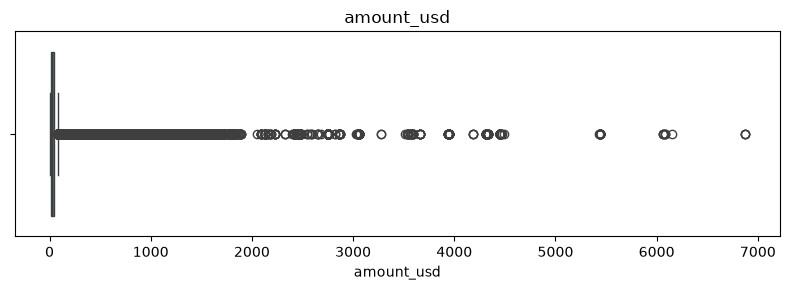

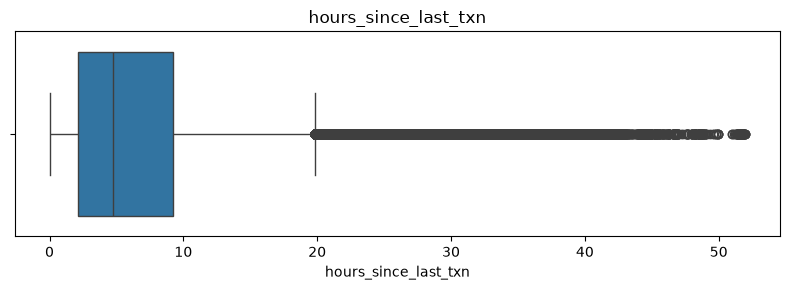

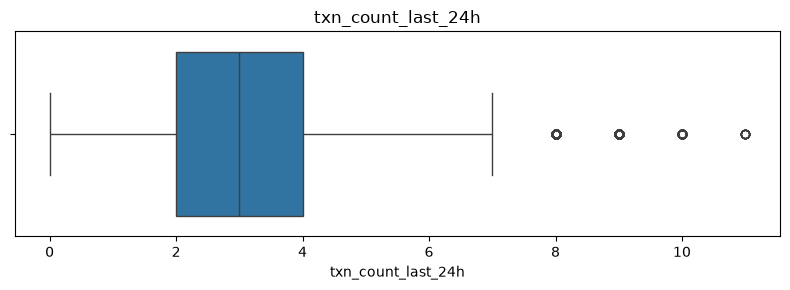

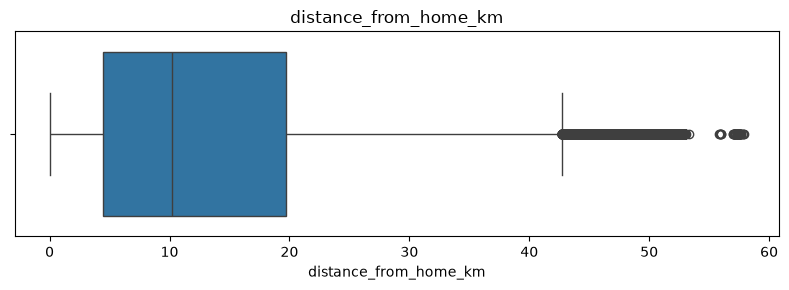

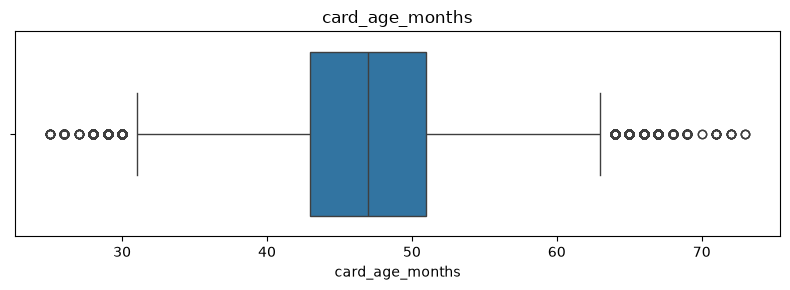

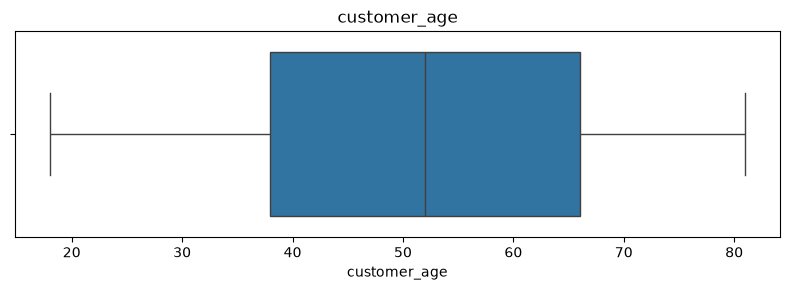

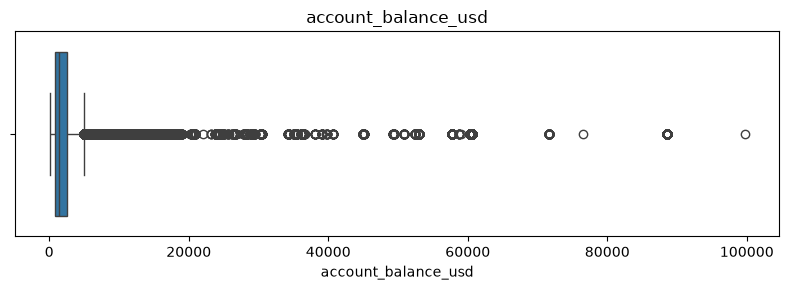

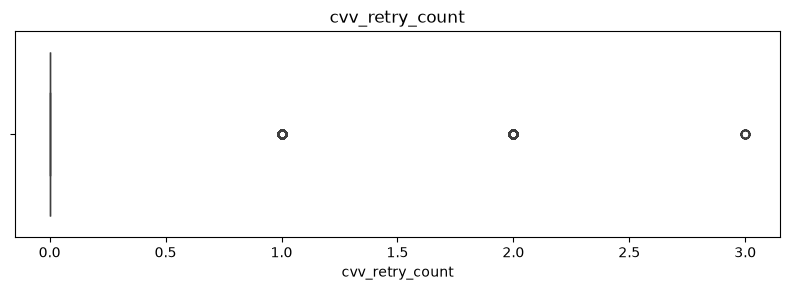

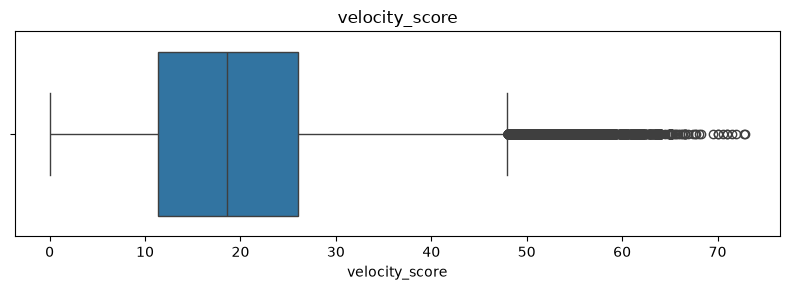

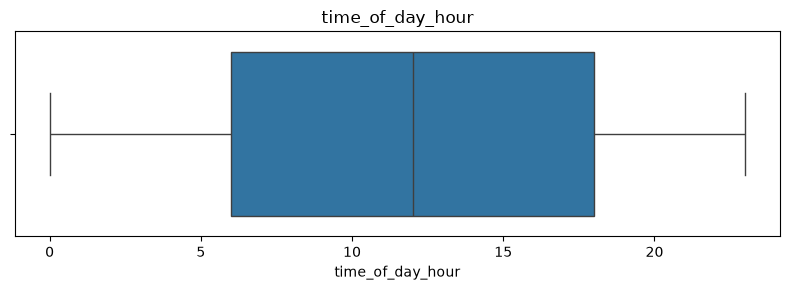

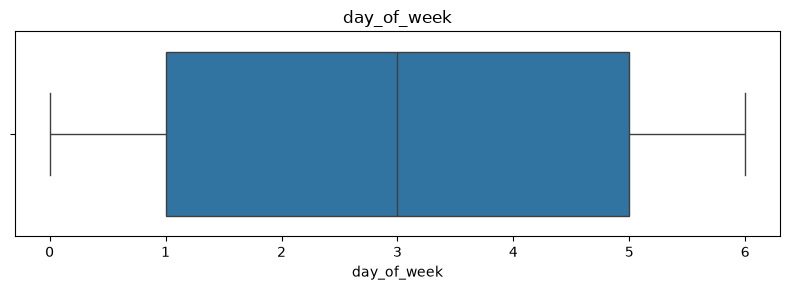

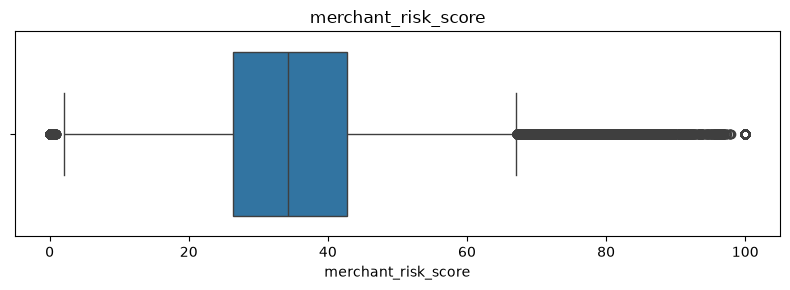

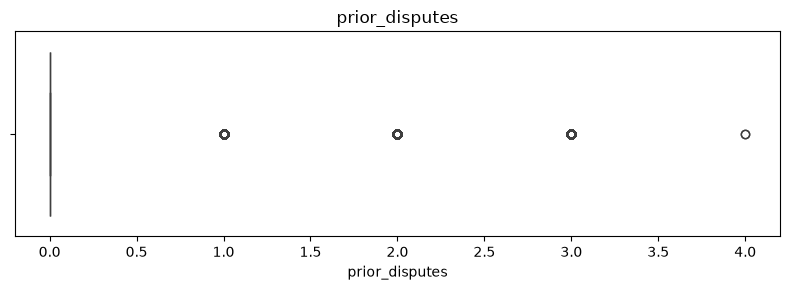

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in X_numerical.columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=X_numerical[col])
    plt.title(col)
    plt.tight_layout()
    plt.show()

Nhận xét: 

#Kiểm tra tương quan tuyến tính giữa các đặc trưng dạng numerical và nhãn

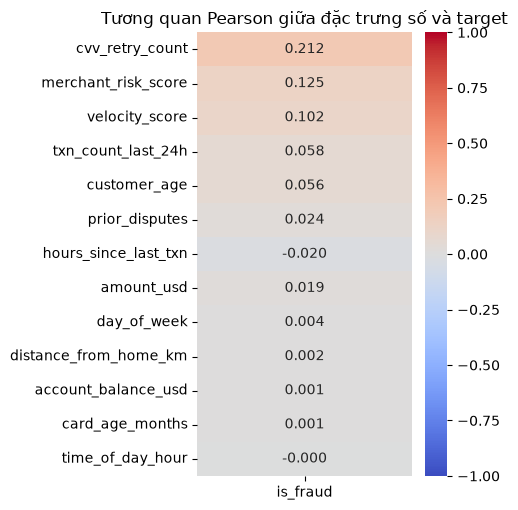

In [80]:

target_col = 'is_fraud'
numeric_cols = X_numerical.columns
corr_target = (
    df[list(numeric_cols) + [target_col]]
    .corr(method="pearson")[[target_col]]
    .drop(index=target_col)
)

corr_target = corr_target.loc[
    corr_target[target_col].abs().sort_values(ascending=False).index
]

plt.figure(figsize=(5, max(4, len(numeric_cols) * 0.4)))
sns.heatmap(
    corr_target,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Tương quan Pearson giữa đặc trưng số và target")
plt.tight_layout()
plt.show()

#Kiểm tra tương quan tuyến tính giữa các đặc trưng dạng numerical với nhau

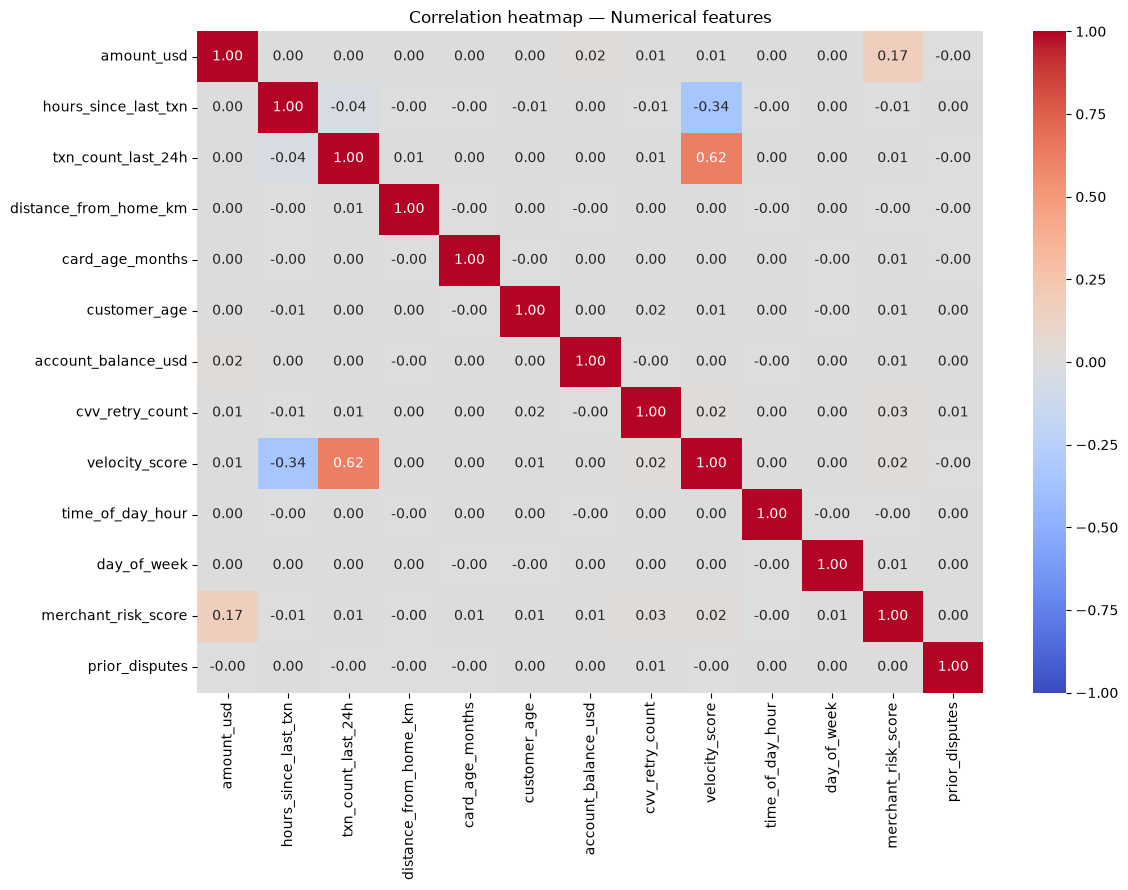

In [81]:

corr_matrix = X_numerical.corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlation heatmap — Numerical features")
plt.tight_layout()
plt.show()

#Nhận xét: Các đặc trưng dạng số có hệ số tương quan tuyến tính với nhãn khá thấp, khoảng từ −0,02 đến 0,2. Điều này cho thấy từng đặc trưng riêng lẻ có mối liên hệ tuyến tính yếu với nhãn, nhưng chưa đủ để kết luận khả năng dự đoán khi kết hợp các đặc trưng. Vì vậy, nên sử dụng Logistic Regression làm mô hình cơ sở và thử nghiệm thêm các mô hình phi tuyến như Decision Tree, Random Forest để khai thác các quan hệ phi tuyến và tương tác giữa các đặc trưng. Việc lựa chọn mô hình cần dựa trên kết quả validation với các chỉ số phù hợp cho dữ liệu mất cân bằng như precision, recall, F1-score.

#Kiểm tra tỉ lệ gian lận trong từng nhóm categorical vaf bool

In [82]:
categorical_cols = X_object.columns.tolist() + X_bool.columns.tolist()
summaries = []
for col in categorical_cols:
    summary = (
        df.groupby(col)["is_fraud"]
        .agg(sample_count="size", fraud_count="sum", fraud_rate="mean")
        .sort_values("fraud_rate", ascending=False)
    )
    summary["fraud_rate"] *= 100
    summaries.append((col, summary))

    print(f"\n--- {col} (fraud_rate: %) ---")
    print(summary)


--- merchant_category (fraud_rate: %) ---
                   sample_count  fraud_count  fraud_rate
merchant_category                                       
Gift Cards                 9456        690.0    7.296954
Crypto Exchange            5285        345.0    6.527909
Gaming                    23784       1311.0    5.512109
Electronics               48693       1501.0    3.082579
Streaming                 47196       1061.0    2.248072
Travel                    28715        534.0    1.859655
Utilities                 42027        581.0    1.382445
Healthcare                35889        462.0    1.287303
Fuel                      59880        741.0    1.237475
Restaurants              101360       1159.0    1.143449
Groceries                142578       1585.0    1.111672
Online Retail            155097       1719.0    1.108339

--- card_type (fraud_rate: %) ---
            sample_count  fraud_count  fraud_rate
card_type                                        
Amex               45797

C:\Users\Long\AppData\Local\Temp\ipykernel_19812\3959435655.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=9)


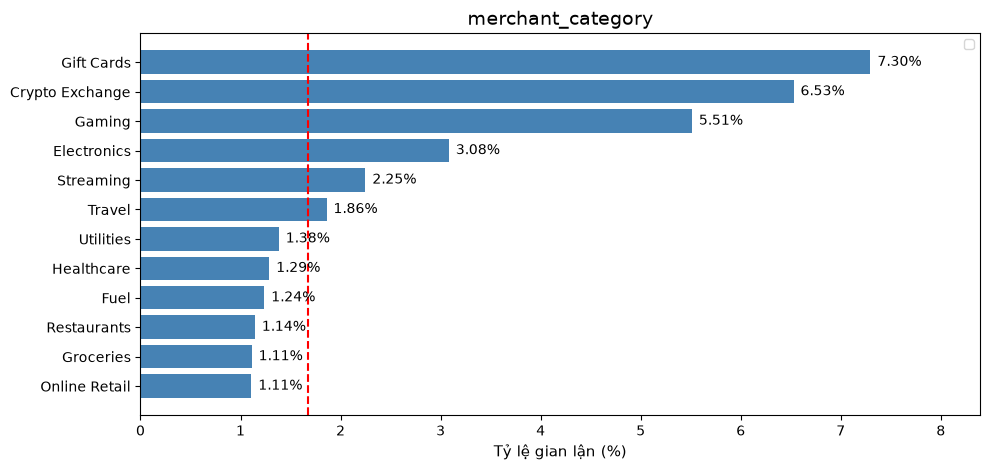

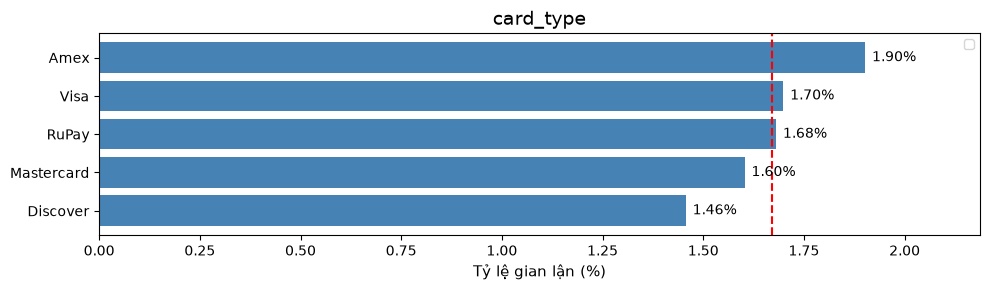

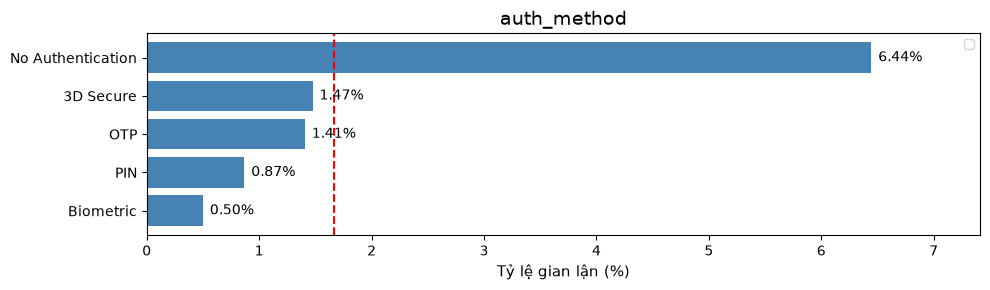

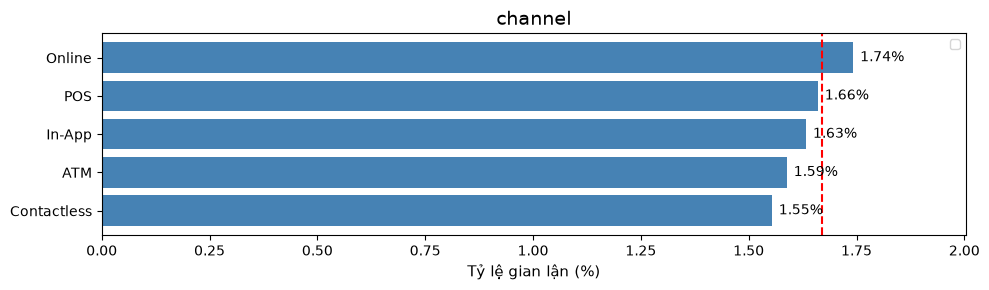

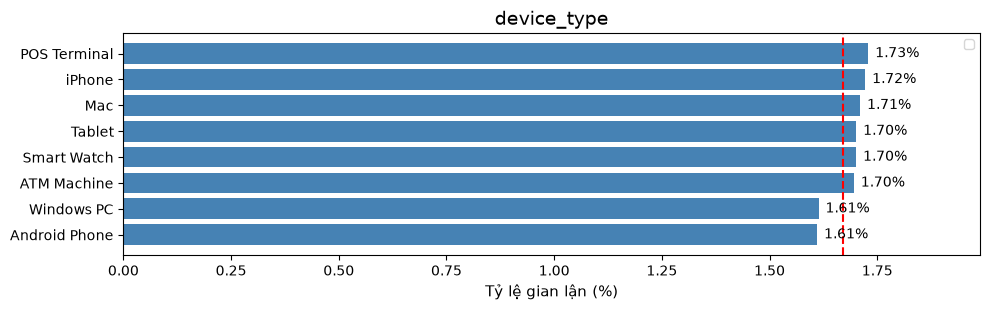

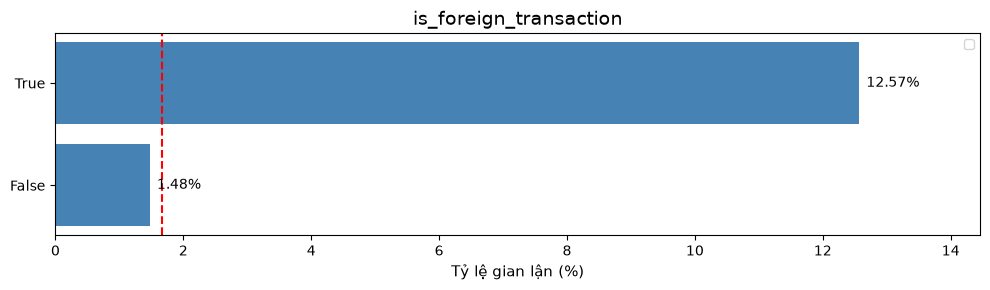

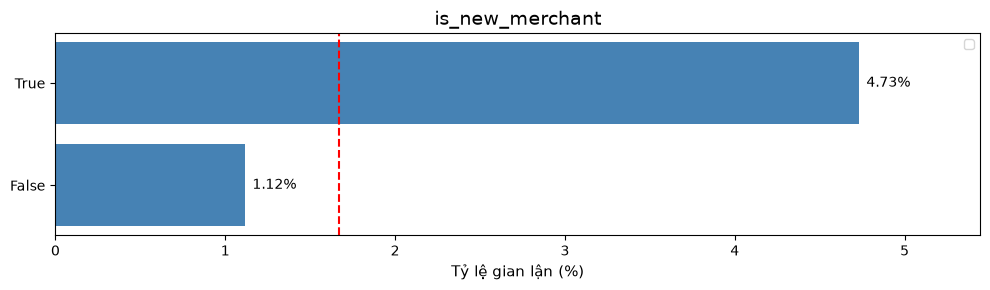

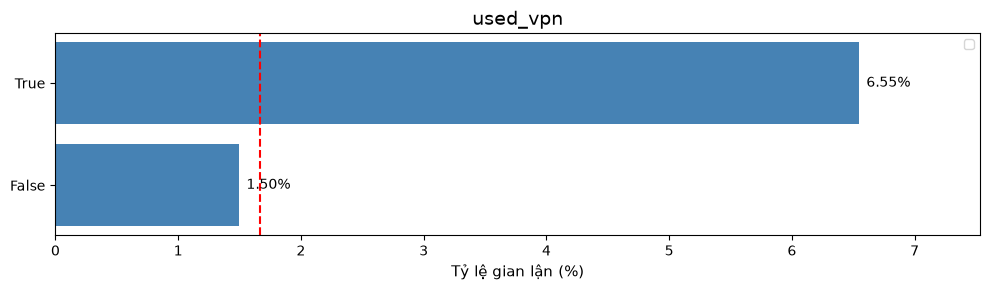

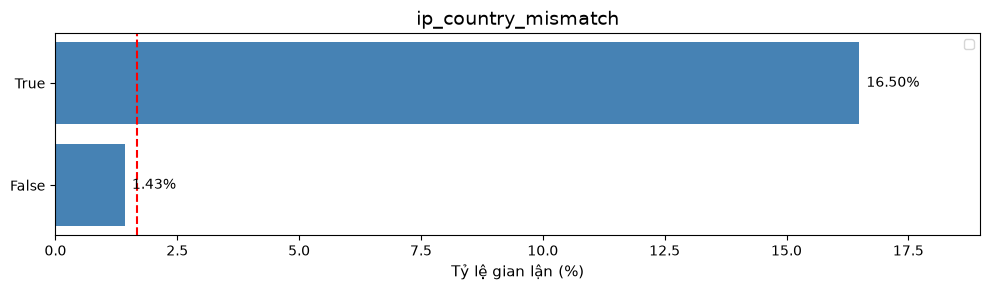

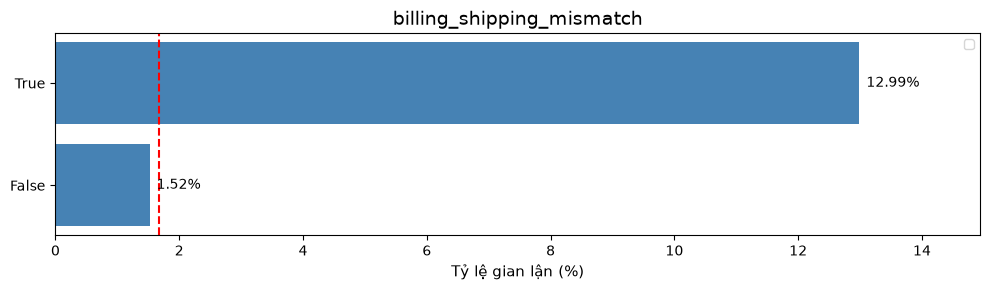

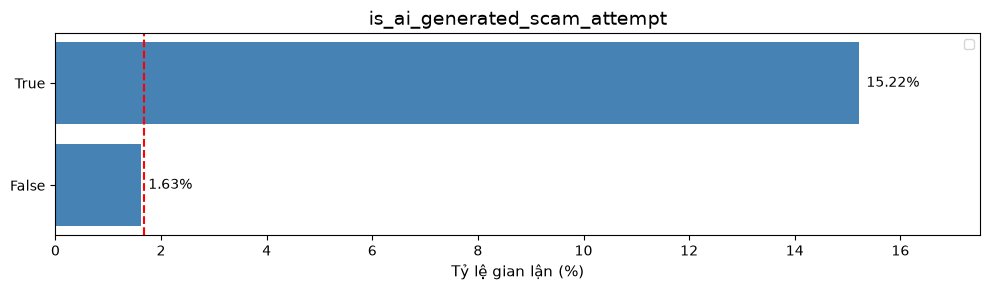

In [83]:
overall_rate = percent_class_1*100  #1.67%

for col, summary in summaries:
    fig, ax = plt.subplots(figsize=(10, max(3, len(summary) * 0.4)))

    bars = ax.barh(
        summary.index.astype(str),
        summary["fraud_rate"],
        color="steelblue",
    )
    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.2f%%", padding=5, fontsize=10)
    ax.axvline(
        overall_rate, color="red", linestyle="--"
    )

    ax.set_title(col, fontsize=14)
    ax.set_xlabel("Tỷ lệ gian lận (%)", fontsize=11)
    ax.tick_params(labelsize=10)
    ax.margins(x=0.15)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

Nhận xét: với đặc trưng dạng categorical tỉ lệ gian lận khác biệt rõ rệt giữa các nhóm thuộc merchant_category và auth_method, cho thấy 2 đăc trưng này có thể có ích cho việc phát hiện giao dịch gian lận. Ngược lại, tỉ lệ gian lận giữa các nhóm của card_type, channel va device_type ít có biến động giữa các lớp nên khả năng phân biệt khi xuất hiện riêng lẻ có thể khó. Với dữ liệu dạng bool các đặc trưng đều có sự biến động lớn giữa 2 lớp True và False. Đặc biệt các đặc trưng như ip_country_mismatch, is_foreign_transaction và is_ai_generated_scam_attempt có sự chênh lệch khá lớn về tỉ lệ gian lận của True so với False. Do đó các đặc trưng dạng bool có thể có ích trong việc hỗ trợ phát hiện gian lận, cần kết hợp các phương pháp kiểm định để làm rõ hơn mức độ liên hệ với nhãn.

## 1.4: Tiền xử lí dữ liệu

#Loại bỏ các đặc trưng categorical tốt hơn


In [84]:
X_object = X_object.drop(columns=['card_type', 'channel', 'device_type'])
X_object

,merchant_category,auth_method
0,Groceries,OTP
1,Online Retail,PIN
2,Utilities,OTP
3,Groceries,3D Secure
4,Electronics,3D Secure
...,...,...
699955,Travel,3D Secure
699956,Restaurants,No Authentication
699957,Online Retail,Biometric
699958,Groceries,PIN


In [85]:
X_features = pd.concat([X_numerical, X_object, X_bool], axis=1)
X_features.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,merchant_risk_score,prior_disputes,merchant_category,auth_method,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,29.2,0,Groceries,OTP,False,False,False,False,False,False
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,29.9,1,Online Retail,PIN,False,False,False,False,False,False
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,24.1,0,Utilities,OTP,False,False,True,False,False,False
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,41.9,0,Groceries,3D Secure,False,False,False,False,False,False
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,48.0,0,Electronics,3D Secure,False,False,False,False,False,False


#Chia train test

In [86]:
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y.astype(int), test_size=0.2, random_state=42, stratify=y
)

#Mã hóa dữ liệu dạng categorical và bool

In [87]:
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer

categorical_cols = X_object.columns.tolist()
bool_cols = X_bool.columns.tolist()

def bool_to_int(data):
    return data.astype("int64")

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_cols,
        ),
        (
            "boolean",
            FunctionTransformer(
                bool_to_int,
                feature_names_out="one-to-one",
            ),
            bool_cols,
        ),
    ],
    remainder="passthrough",  # Giữ nguyên các cột numerical
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

X_train.head()
print(f"X_train shape: {X_train.shape}")

X_train shape: (559968, 36)


## 1.5: Lựa chọn đặc trưng

#pp kiểm định chi2

In [88]:

import numpy as np
import pandas as pd
from sklearn.feature_selection import chi2

K = 12
feature_names = preprocessor.get_feature_names_out()
encoded_cols = []
for group in ['categorical', 'boolean']:
    encoded_cols.extend(feature_names[preprocessor.output_indices_[group]].tolist())
numeric_cols = feature_names[preprocessor.output_indices_['remainder']].tolist()

X_chi2 = X_train.loc[:, encoded_cols]
if not np.isfinite(X_chi2.to_numpy()).all() or (X_chi2 < 0).any().any():
    raise ValueError('Các cột dùng chi2 phải hữu hạn và không âm.')

scores, p_values = chi2(X_chi2, y_train)
chi2_results = pd.DataFrame({
    'feature': encoded_cols,
    'chi2': scores,
    'p_value': p_values,
}).sort_values('chi2', ascending=False, kind='stable').reset_index(drop=True)

valid_results = chi2_results[np.isfinite(chi2_results['chi2'])]
if not isinstance(K, int) or not 1 <= K <= len(valid_results):
    raise ValueError(f'K phải là số nguyên từ 1 đến {len(valid_results)}.')
top_cols = valid_results.head(K)['feature'].tolist()
selected_cols = numeric_cols + top_cols
chi2_results['selected'] = chi2_results['feature'].isin(top_cols)

X_train_selected = X_train.loc[:, selected_cols].copy()
X_test_selected = X_test.loc[:, selected_cols].copy()

print(f'Chọn {K}/{len(encoded_cols)} cột one-hot/boolean, giữ {len(numeric_cols)} cột numerical.')
print('X_train_selected:', X_train_selected.shape)
print('X_test_selected:', X_test_selected.shape)
display(chi2_results)


Chọn 12/23 cột one-hot/boolean, giữ 13 cột numerical.
X_train_selected: (559968, 25)
X_test_selected: (139992, 25)


,feature,chi2,p_value,selected
0,ip_country_mismatch,12273.376111,0.000000e+00,True
1,auth_method_No Authentication,7570.197679,0.000000e+00,True
2,is_foreign_transaction,7015.570778,0.000000e+00,True
3,billing_shipping_mismatch,5617.357973,0.000000e+00,True
4,is_new_merchant,4619.680324,0.000000e+00,True
5,used_vpn,2633.755003,0.000000e+00,True
6,is_ai_generated_scam_attempt,2053.425385,0.000000e+00,True
7,merchant_category_Gaming,1750.263002,0.000000e+00,True
8,merchant_category_Gift Cards,1392.608656,8.483732e-305,True
9,merchant_category_Crypto Exchange,637.110990,1.419907e-140,True


## 1.6: Feature Engineering

### Thử SMOTE và ADASYN trên lớp gian lận

Dùng hồi quy logistic với cùng cấu hình cho ba lần huấn luyện: dữ liệu gốc, SMOTE và ADASYN. Cả hai phương pháp dùng 5 láng giềng và nhắm tới 1 mẫu gian lận trên 10 mẫu hợp lệ trong tập huấn luyện. SMOTE nội suy giữa các mẫu gian lận gần nhau. ADASYN tạo nhiều mẫu hơn quanh các ca gian lận có nhiều giao dịch hợp lệ lân cận.

Chuẩn hóa 13 cột số theo tập huấn luyện trước khi tìm láng giềng. Các cột one-hot và Boolean giữ thang 0–1; phép nội suy có thể tạo giá trị phân số ở các cột này. Các mẫu tổng hợp chỉ dùng làm đầu vào số cho mô hình. Đánh giá trên tập giữ lại ở mục 1.4 với tỷ lệ gian lận gốc. Ưu tiên Average Precision (AP) để so sánh khả năng xếp hạng và dùng ngưỡng 0,5 cho precision, recall và F1 của lớp gian lận.

In [89]:
from imblearn.over_sampling import ADASYN, SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import StandardScaler

sampling_scaler = ColumnTransformer(
    [('numeric', StandardScaler(), numeric_cols)],
    remainder='passthrough',
)
sampling_train = sampling_scaler.fit_transform(X_train_selected)
sampling_holdout = sampling_scaler.transform(X_test_selected)


def evaluate_sampling(name, sampler):
    X_fit, y_fit = sampling_train, y_train
    if sampler is not None:
        X_fit, y_fit = sampler.fit_resample(X_fit, y_fit)

    model = LogisticRegression(max_iter=500)
    model.fit(X_fit, y_fit)
    scores = model.predict_proba(sampling_holdout)[:, 1]
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, scores >= 0.5, average='binary', zero_division=0
    )
    return {
        'Phương pháp': name,
        'Mẫu hợp lệ (train)': int((y_fit == 0).sum()),
        'Mẫu gian lận (train)': int((y_fit == 1).sum()),
        'AP': average_precision_score(y_test, scores),
        'ROC-AUC': roc_auc_score(y_test, scores),
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
    }


sampling_methods = {
    'Dữ liệu gốc': None,
    'SMOTE': SMOTE(sampling_strategy=0.1, k_neighbors=5, random_state=42),
    'ADASYN': ADASYN(sampling_strategy=0.026, n_neighbors=8, random_state=42),
}
sampling_results = pd.DataFrame(
    [evaluate_sampling(name, sampler) for name, sampler in sampling_methods.items()]
).set_index('Phương pháp')
display(sampling_results.round(4))

,Mẫu hợp lệ (train),Mẫu gian lận (train),AP,ROC-AUC,Precision,Recall,F1
Phương pháp,,,,,,,
Dữ liệu gốc,550617,9351,0.4916,0.9391,0.7581,0.3015,0.4315
SMOTE,550617,55061,0.4889,0.9386,0.3814,0.5565,0.4526
ADASYN,550617,16028,0.4907,0.9388,0.6525,0.3678,0.4705


**Nhận xét trên 139.992 giao dịch giữ lại.** Với hồi quy logistic, dữ liệu gốc đạt AP cao nhất (0,4916). Ở ngưỡng 0,5, SMOTE tăng recall từ 30,15% lên 55,65% và đạt F1 cao nhất (0,4526), đồng thời precision giảm từ 75,81% xuống 38,14%. ADASYN phát hiện tỷ lệ gian lận cao nhất (recall 56,67%), với precision 36,33%. Kết quả này áp dụng cho lần chia dữ liệu và cấu hình đã thử.

## 1.7. Khám phá dữ liệu test

Phần này đọc trực tiếp `data/test.csv` và có thể chạy độc lập. Tập test không có nhãn `is_fraud`, nên phần phân tích theo nhóm sử dụng số lượng và tỷ trọng giao dịch.

### Cấu trúc dữ liệu và giá trị thiếu

In [90]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

test_features = pd.read_csv("data/test.csv").drop(columns="id")
test_features.info()
display(test_features.isna().sum().rename("Số giá trị thiếu").to_frame())

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 0 to 299983
Data columns (total 24 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    299984 non-null  float64
 1   hours_since_last_txn          299984 non-null  float64
 2   txn_count_last_24h            299984 non-null  int64  
 3   distance_from_home_km         299984 non-null  float64
 4   card_age_months               299984 non-null  int64  
 5   customer_age                  299984 non-null  int64  
 6   account_balance_usd           299984 non-null  float64
 7   cvv_retry_count               299984 non-null  int64  
 8   velocity_score                299984 non-null  float64
 9   time_of_day_hour              299984 non-null  int64  
 10  day_of_week                   299984 non-null  int64  
 11  merchant_risk_score           299984 non-null  float64
 12  prior_disputes                299984 non-null  int64  


,Số giá trị thiếu
amount_usd,0
hours_since_last_txn,0
txn_count_last_24h,0
distance_from_home_km,0
card_age_months,0
customer_age,0
account_balance_usd,0
cvv_retry_count,0
velocity_score,0
time_of_day_hour,0


### Phân loại đặc trưng

In [91]:
test_numeric = test_features.select_dtypes(include="number")
test_categorical = test_features.select_dtypes(exclude=["number", "bool"])
test_bool = test_features.select_dtypes(include="bool")

for test_label, test_group in [
    ("Dạng số", test_numeric),
    ("Dạng phân loại", test_categorical),
    ("Dạng boolean", test_bool),
]:
    print(f"{test_label} ({test_group.shape[1]} đặc trưng)")
    display(test_group.head())

Dạng số (13 đặc trưng)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes
0,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,21,3,22.1,0
1,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,9,1,25.1,0
2,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,2,4,52.9,1
3,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,8,5,35.4,0
4,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,14,5,44.5,0


Dạng phân loại (5 đặc trưng)


,merchant_category,card_type,auth_method,channel,device_type
0,Fuel,Visa,OTP,Online,iPhone
1,Travel,RuPay,PIN,Contactless,Android Phone
2,Gaming,Visa,No Authentication,Online,iPhone
3,Streaming,Mastercard,PIN,Contactless,Mac
4,Groceries,Mastercard,PIN,In-App,Android Phone


Dạng boolean (6 đặc trưng)


,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False


### Giá trị ngoại lệ của đặc trưng số

Các điểm nằm ngoài khoảng từ Q1 − 1,5 × IQR đến Q3 + 1,5 × IQR được đánh dấu trên boxplot. Với biến đếm có Q1 = Q3 = 0, mọi giá trị dương đều nằm ngoài khoảng này dù có thể là quan sát hợp lệ.

,Số giao dịch ngoài khoảng,Tỷ lệ (%)
prior_disputes,43775,14.59
amount_usd,30523,10.17
cvv_retry_count,24795,8.27
hours_since_last_txn,13951,4.65
account_balance_usd,12375,4.13
distance_from_home_km,7043,2.35
merchant_risk_score,5416,1.81
velocity_score,1714,0.57
txn_count_last_24h,1196,0.40
card_age_months,950,0.32


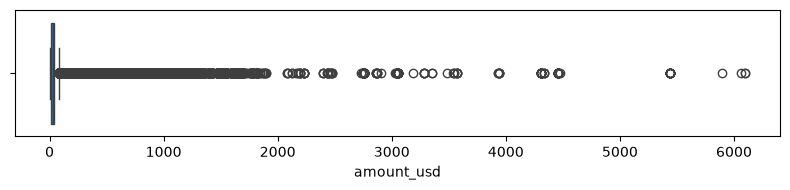

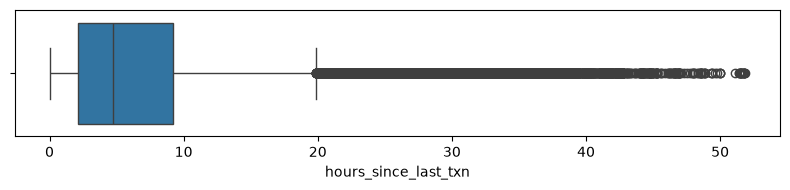

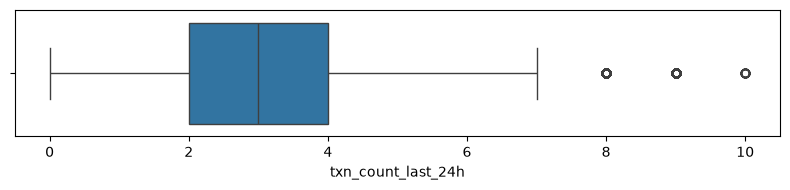

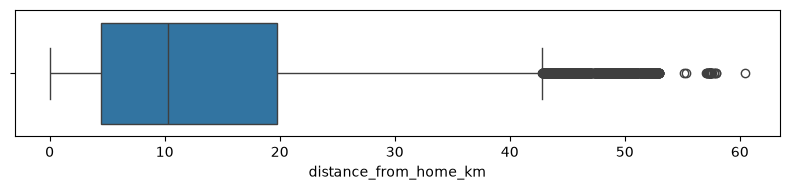

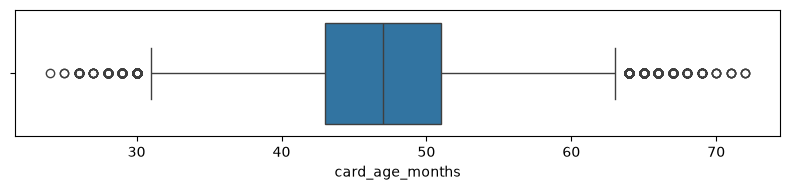

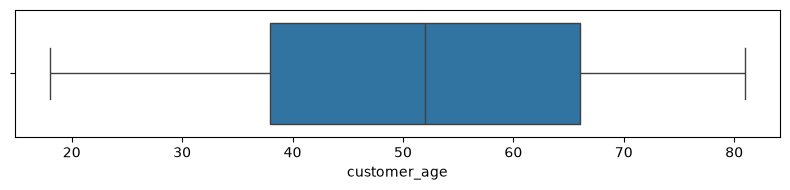

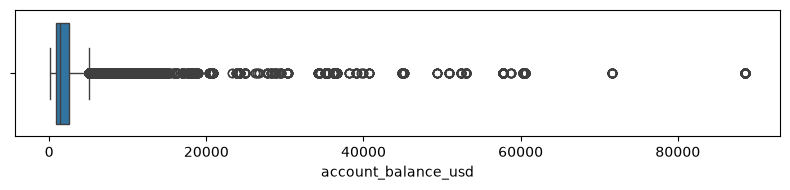

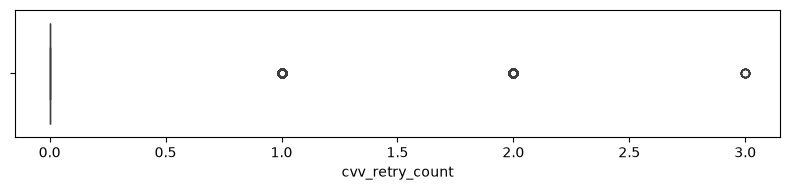

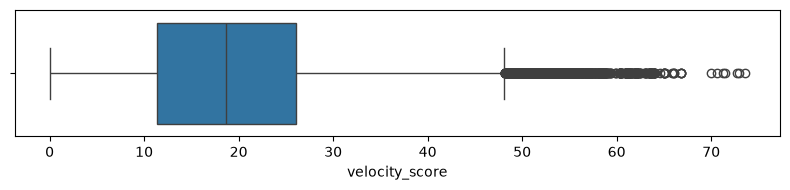

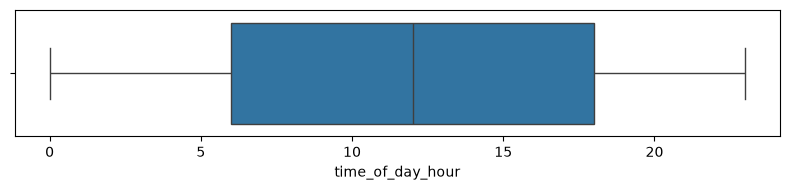

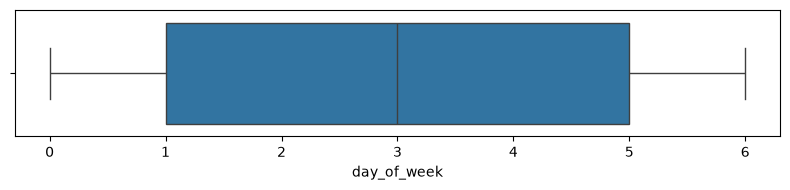

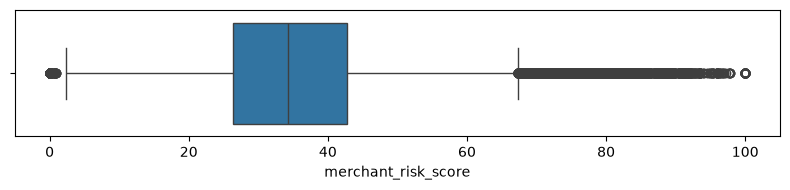

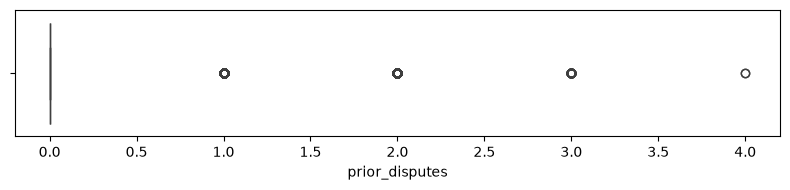

In [92]:
test_q1 = test_numeric.quantile(0.25)
test_q3 = test_numeric.quantile(0.75)
test_iqr = test_q3 - test_q1
test_outliers = (test_numeric < test_q1 - 1.5 * test_iqr) | (test_numeric > test_q3 + 1.5 * test_iqr)
display(pd.DataFrame({
    "Số giao dịch ngoài khoảng": test_outliers.sum(),
    "Tỷ lệ (%)": (100 * test_outliers.sum() / test_numeric.count()).round(2),
}).sort_values("Số giao dịch ngoài khoảng", ascending=False))

for test_col in test_numeric:
    plt.figure(figsize=(8, 2))
    sns.boxplot(x=test_numeric[test_col])
    plt.tight_layout()
    plt.show()

### Tương quan Pearson giữa các đặc trưng số

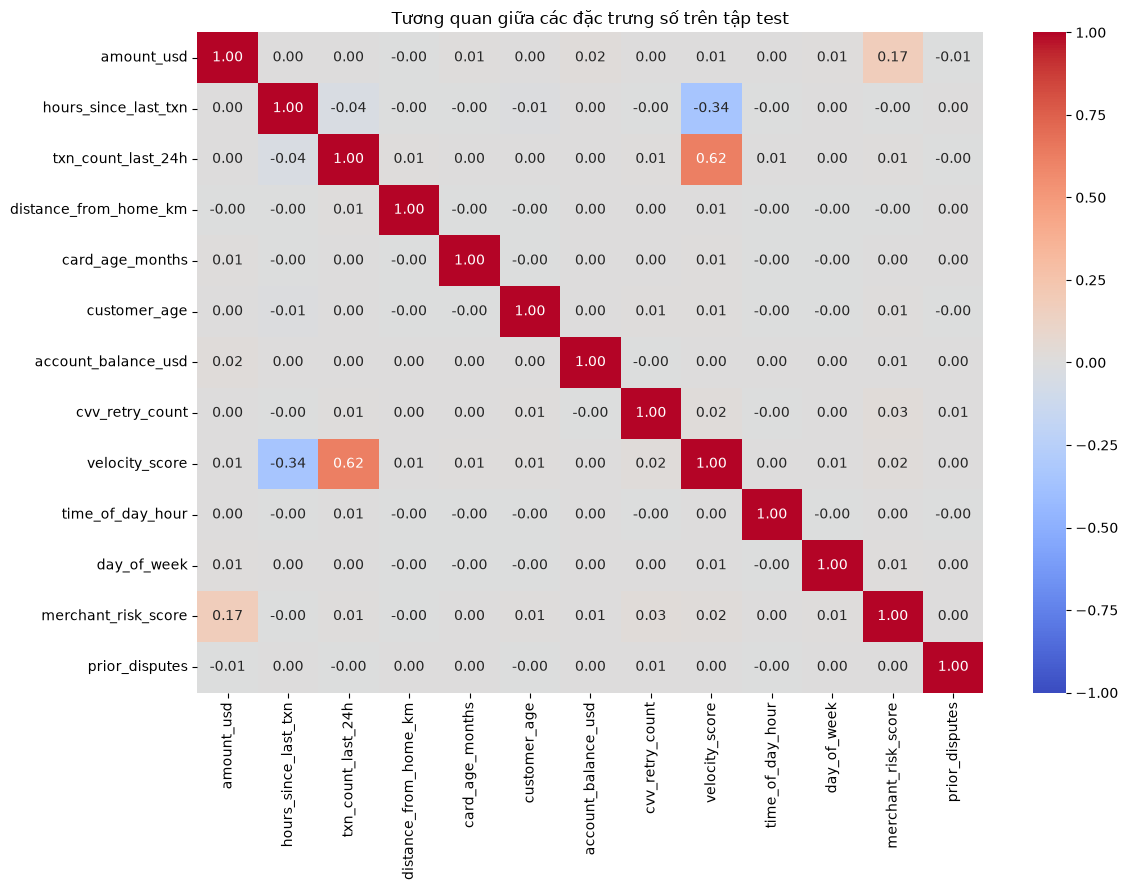

In [93]:
test_corr = test_numeric.corr(method="pearson")
plt.figure(figsize=(12, 9))
sns.heatmap(test_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Tương quan giữa các đặc trưng số trên tập test")
plt.tight_layout()
plt.show()

### Phân bố các đặc trưng phân loại và boolean

Tỷ trọng của mỗi nhóm là số giao dịch trong nhóm chia cho tổng số giao dịch của tập test.

,Số giao dịch,Tỷ trọng (%)
merchant_category,,
Online Retail,66608,22.20
Groceries,61338,20.45
Restaurants,43130,14.38
Fuel,25867,8.62
Electronics,20870,6.96
Streaming,19943,6.65
Utilities,17952,5.98
Healthcare,15456,5.15
Travel,12275,4.09


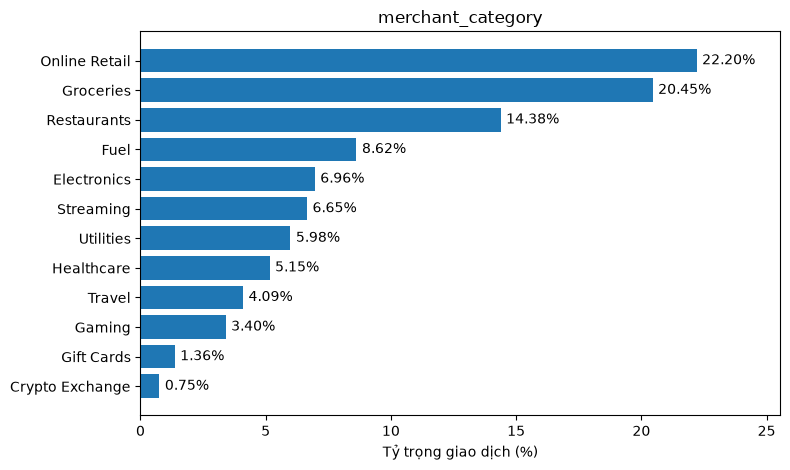

,Số giao dịch,Tỷ trọng (%)
card_type,,
Visa,148119,49.38
Mastercard,109085,36.36
Amex,19541,6.51
RuPay,15775,5.26
Discover,7464,2.49


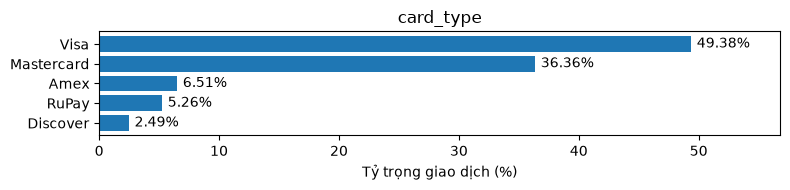

,Số giao dịch,Tỷ trọng (%)
auth_method,,
3D Secure,90042,30.02
OTP,75492,25.17
PIN,66181,22.06
Biometric,40222,13.41
No Authentication,28047,9.35


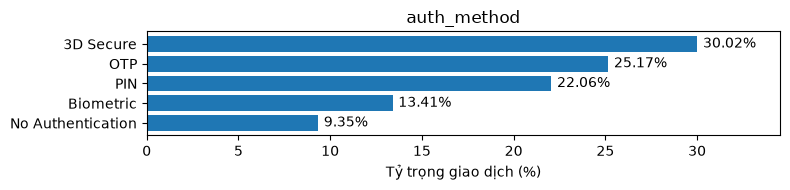

,Số giao dịch,Tỷ trọng (%)
channel,,
Online,117066,39.02
POS,88730,29.58
Contactless,45664,15.22
In-App,35598,11.87
ATM,12926,4.31


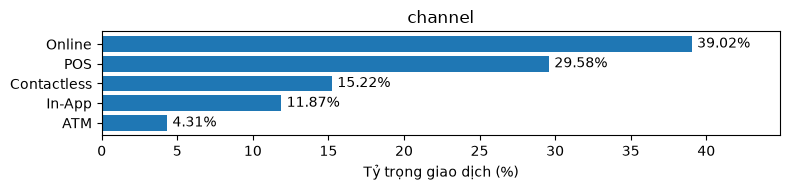

,Số giao dịch,Tỷ trọng (%)
device_type,,
Android Phone,101479,33.83
iPhone,70422,23.48
POS Terminal,48702,16.23
Windows PC,34669,11.56
Mac,14607,4.87
Tablet,11910,3.97
Smart Watch,9210,3.07
ATM Machine,8985,3.00


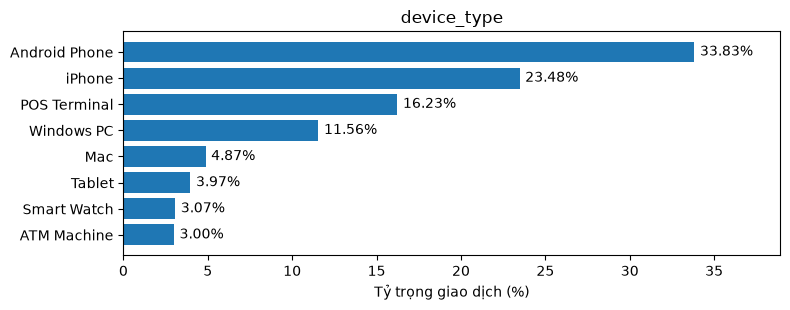

,Số giao dịch,Tỷ trọng (%)
is_foreign_transaction,,
False,294766,98.26
True,5218,1.74


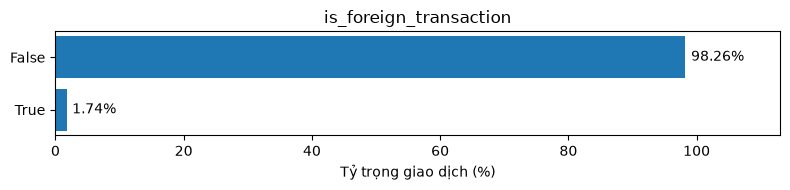

,Số giao dịch,Tỷ trọng (%)
is_new_merchant,,
False,254138,84.72
True,45846,15.28


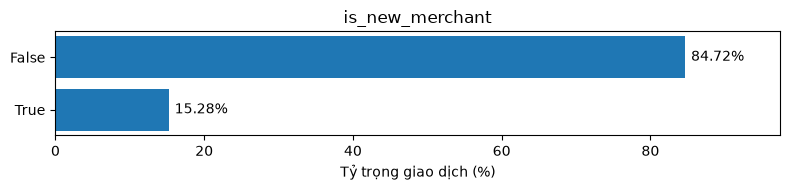

,Số giao dịch,Tỷ trọng (%)
used_vpn,,
False,290094,96.7
True,9890,3.3


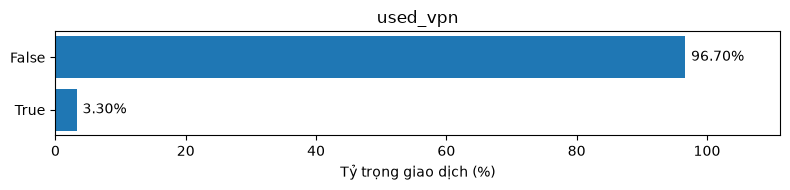

,Số giao dịch,Tỷ trọng (%)
ip_country_mismatch,,
False,295174,98.4
True,4810,1.6


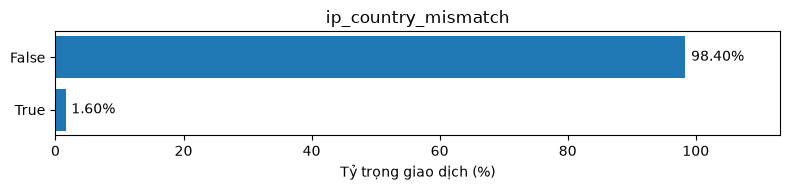

,Số giao dịch,Tỷ trọng (%)
billing_shipping_mismatch,,
False,296058,98.69
True,3926,1.31


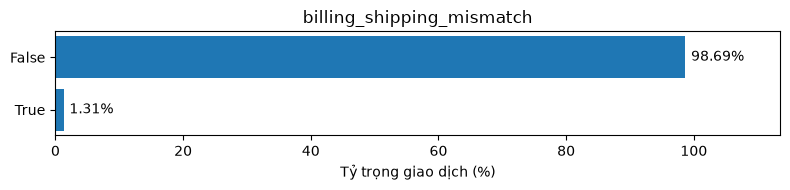

,Số giao dịch,Tỷ trọng (%)
is_ai_generated_scam_attempt,,
False,298955,99.66
True,1029,0.34


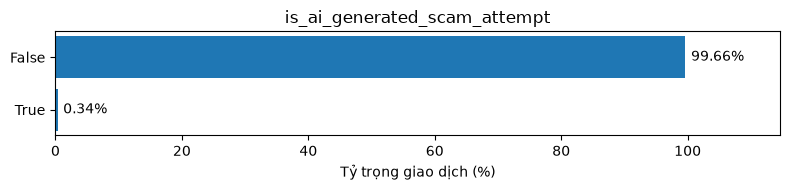

In [94]:
for test_col in [*test_categorical.columns, *test_bool.columns]:
    test_counts = test_features[test_col].value_counts(dropna=False)
    test_summary = test_counts.rename("Số giao dịch").to_frame()
    test_summary["Tỷ trọng (%)"] = 100 * test_counts / len(test_features)
    display(test_summary.round(2))

    test_fig, test_ax = plt.subplots(figsize=(8, max(2, len(test_summary) * 0.4)))
    test_bars = test_ax.barh(test_counts.index.astype(str), test_summary["Tỷ trọng (%)"])
    test_ax.invert_yaxis()
    test_ax.bar_label(test_bars, fmt="%.2f%%", padding=4)
    test_ax.set(xlabel="Tỷ trọng giao dịch (%)", title=test_col)
    test_ax.margins(x=0.15)
    test_fig.tight_layout()
    plt.show()

**Nhận xét trên tập test**

- Có 299.984 giao dịch và 24 đặc trưng sau khi bỏ `id`. Cả 13 cột số, 5 cột phân loại và 6 cột boolean đều đầy đủ dữ liệu.
- Có 30.523 giao dịch có `amount_usd` nằm ngoài khoảng 1,5 × IQR tính từ hai tứ phân vị.
- Cặp `txn_count_last_24h` và `velocity_score` có tương quan tuyến tính mạnh nhất về độ lớn (r ≈ 0,62). Giao dịch có số lần giao dịch trong 24 giờ cao hơn thường có điểm tốc độ cao hơn.
- Trong `merchant_category`, Online Retail chiếm 22,20% giao dịch và Groceries chiếm 20,45%.

## 1.8. So sánh phân phối giữa train và test

Đọc toàn bộ hai tệp gốc để so sánh các đặc trưng trước khi tiền xử lý. Loại mã giao dịch `id` và nhãn `is_fraud` khỏi phép so sánh. Mỗi tỷ lệ được tính trên tập tương ứng.

In [95]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

dist_train = pd.read_csv("data/train.csv").drop(columns=["id", "is_fraud"])
dist_test = pd.read_csv("data/test.csv").drop(columns="id")
if set(dist_train.columns) != set(dist_test.columns):
    raise ValueError("Hai tập có danh sách đặc trưng khác nhau.")

dist_overview = pd.DataFrame({
    name: {
        "Số giao dịch": len(frame),
        "Số đặc trưng": frame.shape[1],
        "Số giá trị thiếu": frame.isna().sum().sum(),
    }
    for name, frame in [("Train", dist_train), ("Test", dist_test)]
})
display(dist_overview)

,Train,Test
Số giao dịch,699960,299984
Số đặc trưng,24,24
Số giá trị thiếu,0,0


### Đặc trưng số

Bảng đối chiếu trung vị và phân vị 99% (P99). Để so sánh toàn bộ phân phối, tại mỗi ngưỡng quan sát được, tính tỷ lệ giao dịch có giá trị nhỏ hơn hoặc bằng ngưỡng đó ở từng tập. Chênh lệch tuyệt đối lớn nhất giữa hai tỷ lệ là khoảng cách Kolmogorov–Smirnov, ở đây biểu diễn bằng điểm phần trăm. Giá trị thiếu được loại khỏi mẫu số của từng cột số.

In [96]:
dist_numeric_cols = dist_train.select_dtypes(include="number").columns
dist_numeric_rows = []
for dist_col in dist_numeric_cols:
    train_values = dist_train[dist_col]
    test_values = dist_test[dist_col]
    dist_cdf = pd.concat([
        train_values.value_counts(normalize=True).rename("Train"),
        test_values.value_counts(normalize=True).rename("Test"),
    ], axis=1).fillna(0).sort_index().cumsum().mul(100)
    dist_gap = (dist_cdf["Test"] - dist_cdf["Train"]).abs()
    dist_threshold = dist_gap.idxmax()
    dist_numeric_rows.append({
        "Đặc trưng": dist_col,
        "Trung vị train": train_values.median(),
        "Trung vị test": test_values.median(),
        "P99 train": train_values.quantile(0.99),
        "P99 test": test_values.quantile(0.99),
        "Ngưỡng": dist_threshold,
        "Train ≤ ngưỡng (%)": dist_cdf.loc[dist_threshold, "Train"],
        "Test ≤ ngưỡng (%)": dist_cdf.loc[dist_threshold, "Test"],
        "KS (điểm %)": dist_gap.max(),
    })

dist_numeric_summary = (pd.DataFrame(dist_numeric_rows).set_index("Đặc trưng")
                        .sort_values("KS (điểm %)", ascending=False))
display(dist_numeric_summary.round(3))

,Trung vị train,Trung vị test,P99 train,P99 test,Ngưỡng,Train ≤ ngưỡng (%),Test ≤ ngưỡng (%),KS (điểm %)
Đặc trưng,,,,,,,,
day_of_week,3.00,3.00,6.00,6.00,3.00,57.370,57.752,0.383
card_age_months,47.00,47.00,60.00,60.00,45.00,41.395,41.661,0.266
merchant_risk_score,34.20,34.20,72.00,71.90,36.70,58.589,58.374,0.215
distance_from_home_km,10.22,10.27,47.86,46.84,6.37,35.145,34.949,0.197
account_balance_usd,1382.74,1388.54,9082.81,9082.81,1682.50,60.303,60.118,0.186
time_of_day_hour,12.00,12.00,23.00,23.00,4.00,19.559,19.715,0.157
amount_usd,27.25,27.28,936.95,940.02,54.75,86.500,86.346,0.153
velocity_score,18.60,18.70,46.10,45.90,24.40,70.313,70.174,0.139
hours_since_last_txn,4.73,4.72,29.38,29.53,2.68,31.532,31.670,0.138


### Đặc trưng phân loại và boolean

Với mỗi đặc trưng, đối chiếu tất cả giá trị xuất hiện ở ít nhất một tập. Cột chênh lệch bằng tỷ trọng test trừ tỷ trọng train, tính bằng điểm phần trăm. Bảng được sắp theo độ lớn của chênh lệch.

In [97]:
dist_group_tables = []
for dist_col in dist_train.columns.difference(dist_numeric_cols, sort=False):
    dist_shares = pd.concat([
        dist_train[dist_col].value_counts(normalize=True, dropna=False).rename("Train (%)"),
        dist_test[dist_col].value_counts(normalize=True, dropna=False).rename("Test (%)"),
    ], axis=1).fillna(0).mul(100)
    dist_shares["Chênh lệch (điểm %)"] = dist_shares["Test (%)"] - dist_shares["Train (%)"]
    dist_group_tables.append(dist_shares.rename_axis("Giá trị").assign(**{"Đặc trưng": dist_col}).reset_index())

dist_group_summary = (pd.concat(dist_group_tables, ignore_index=True)
                      .set_index(["Đặc trưng", "Giá trị"])
                      .sort_values("Chênh lệch (điểm %)", key=abs, ascending=False))
with pd.option_context("display.max_rows", None):
    display(dist_group_summary.round(3))

Train (%)  Test (%)  \
Đặc trưng                    Giá trị                                  
auth_method                  No Authentication      9.581     9.349   
                             OTP                   25.027    25.165   
channel                      Contactless           15.089    15.222   
                             Online                39.136    39.024   
merchant_category            Restaurants           14.481    14.377   
device_type                  Android Phone         33.924    33.828   
merchant_category            Streaming              6.743     6.648   
channel                      In-App                11.960    11.867   
card_type                    Visa                  49.289    49.376   
used_vpn                     False                 96.619    96.703   
                             True                   3.381     3.297   
channel                      POS                   29.497    29.578   
merchant_category            Groceries             20.369    20.447   
                             Fuel                   8.555     8.623   
auth_method                  PIN                   22.004    22.062   
device_type                  POS Terminal          16.178    16.235   
                             Smart Watch            3.015     3.070   
                             iPhone                23.529    23.475   
card_type                    Mastercard            36.410    36.364   
merchant_category            Online Retail         22.158    22.204   
card_type                    RuPay                  5.296     5.259   
is_new_merchant              True                  15.247    15.283   
                             False                 84.753    84.717   
card_type                    Amex                   6.543     6.514   
auth_method                  Biometric             13.382    13.408   
card_type                    Discover               2.462     2.488   
merchant_category            Healthcare             5.127     5.152   
                             Utilities              6.004     5.984   
device_type                  Mac                    4.854     4.869   
billing_shipping_mismatch    True                   1.294     1.309   
                             False                 98.706    98.691   
is_ai_generated_scam_attempt True                   0.328     0.343   
                             False                 99.672    99.657   
device_type                  Tablet                 3.956     3.970   
merchant_category            Gift Cards             1.351     1.365   
ip_country_mismatch          True                   1.616     1.603   
                             False                 98.384    98.397   
device_type                  ATM Machine            2.983     2.995   
is_foreign_transaction       False                 98.272    98.261   
                             True                   1.728     1.739   
merchant_category            Travel                 4.102     4.092   
auth_method                  3D Secure             30.007    30.016   
channel                      ATM                    4.317     4.309   
device_type                  Windows PC            11.563    11.557   
merchant_category            Crypto Exchange        0.755     0.753   
                             Gaming                 3.398     3.397   
                             Electronics            6.957     6.957   

                                                Chênh lệch (điểm %)  
Đặc trưng                    Giá trị                                 
auth_method                  No Authentication               -0.231  
                             OTP                              0.138  
channel                      Contactless                      0.133  
                             Online                          -0.112  
merchant_category            Restaurants                     -0.103  
device_type                  Android Phone                   -0.096  
merchant

### Hai đặc trưng có chênh lệch lớn nhất trong từng loại

Biểu đồ bên trái ghi tỷ lệ tích lũy đến từng ngưỡng của đặc trưng số đứng đầu bảng KS. Biểu đồ bên phải đối chiếu tỷ trọng từng nhóm của đặc trưng đứng đầu bảng phân loại và boolean.

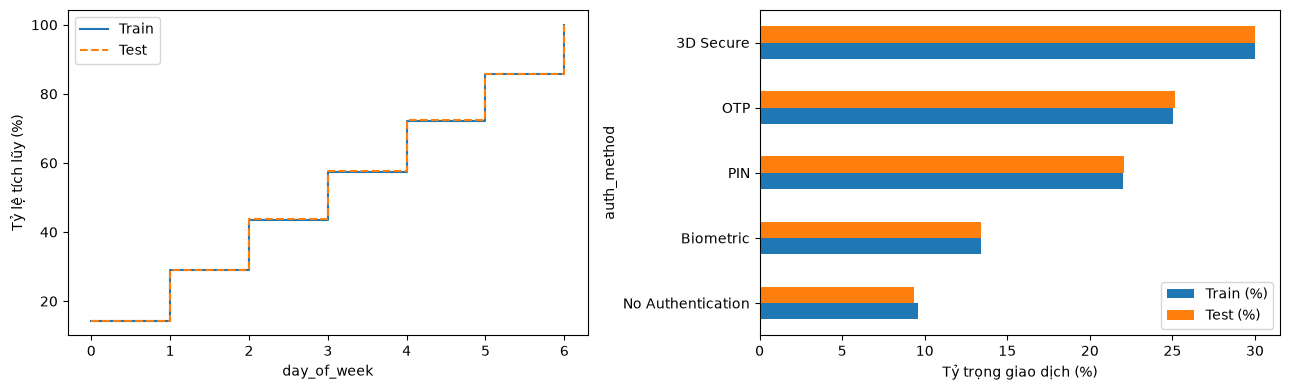

In [98]:
dist_top_num = dist_numeric_summary.index[0]
dist_top_group = dist_group_summary.index[0][0]
dist_fig, dist_axes = plt.subplots(1, 2, figsize=(13, 4))

for dist_name, dist_frame, dist_style in [("Train", dist_train, "-"), ("Test", dist_test, "--")]:
    dist_curve = dist_frame[dist_top_num].value_counts(normalize=True).sort_index().cumsum().mul(100)
    dist_axes[0].step(dist_curve.index, dist_curve, where="post", linestyle=dist_style, label=dist_name)
dist_axes[0].set(xlabel=dist_top_num, ylabel="Tỷ lệ tích lũy (%)")
dist_axes[0].legend()

dist_group_summary.loc[dist_top_group, ["Train (%)", "Test (%)"]].sort_values("Train (%)").plot.barh(ax=dist_axes[1])
dist_axes[1].set(xlabel="Tỷ trọng giao dịch (%)", ylabel=dist_top_group)
dist_fig.tight_layout()
plt.show()

**Nhận xét**

- Hai tập có phân phối gần nhau khi xét riêng từng đặc trưng trên 699.960 giao dịch train và 299.984 giao dịch test. Cả 24 đặc trưng đều đầy đủ ở hai tập.
- Trong 13 đặc trưng số, `day_of_week` có chênh lệch tích lũy lớn nhất. Tỷ lệ giao dịch có `day_of_week ≤ 3` là 57,37% ở train và 57,75% ở test, chênh 0,38 điểm phần trăm.
- Giá trị giao dịch `amount_usd` cũng gần nhau ở cả trung vị (27,25 USD ở train và 27,28 USD ở test) và P99 (936,95 USD và 940,02 USD).
- Cả 11 đặc trưng phân loại và boolean đều có cùng tập giá trị quan sát được. Chênh lệch nhóm lớn nhất thuộc về `No Authentication` của `auth_method`, giảm từ 9,58% ở train xuống 9,35% ở test (0,23 điểm phần trăm).

# 2: Model

## 2.1: Traditional ML

### Decision Tree

In [99]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

X_train_fit, y_train_fit = sampling_methods['ADASYN'].fit_resample(X_train_selected, y_train)
tree_model = Pipeline([
    ('tree', DecisionTreeClassifier(
        max_depth = 8,
        max_leaf_nodes=50,
        splitter = 'random',
        class_weight='balanced',
        random_state=42
    )),
])

tree_model.fit(X_train_fit, y_train_fit)
print('Đã huấn luyện xong Decision Tree!')

Đã huấn luyện xong Decision Tree!


### Random forest

In [100]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

X_train_fit, y_train_fit = sampling_methods['ADASYN'].fit_resample(X_train_selected, y_train)
rf_model = Pipeline([
    ('forest', RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=50,
        class_weight={0:1, 1:10},
        random_state=42,
        n_jobs=2,
    )),
])

rf_model.fit(X_train_fit, y_train_fit)
print('Đã huấn luyện xong Random Forest!')


Đã huấn luyện xong Random Forest!


### XGboost

In [101]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    classification_report, confusion_matrix,
)

X_train_fit, y_train_fit = sampling_methods['ADASYN'].fit_resample(X_train_selected, y_train)
xgb_model = XGBClassifier(
    objective='binary:logistic',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=10,
    tree_method='hist',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=2,
)
xgb_model.fit(X_train_fit, y_train_fit)
print('Đã huấn luyện xong XGBoots!')




Đã huấn luyện xong XGBoots!


## 2.2: MLP

### Simple 2 layer MLP

In [102]:
from sklearn.neural_network import MLPClassifier

X_train_fit, y_train_fit = sampling_methods['ADASYN'].fit_resample(X_train_selected, y_train)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    batch_size=512,
    max_iter=100,
    random_state=42,
    solver='adam',
)
mlp_model.fit(X_train_fit, y_train_fit)
print('Đã huấn luyện xong MLP!')

Đã huấn luyện xong MLP!


### Random Forest + MLP

In [104]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

# Chia riêng dữ liệu học của rừng và MLP, giữ tỷ lệ gian lận ở cả hai phần.
X_train_fit, y_train_fit = sampling_methods['ADASYN'].fit_resample(X_train_selected, y_train)
X_forest, X_head, y_forest, y_head = train_test_split(
    X_train_fit, y_train_fit, test_size=0.25, stratify=y_train_fit, random_state=42
)
hybrid_forest = RandomForestClassifier(
    n_estimators=100, max_depth=8, min_samples_leaf=50,
    class_weight={0: 1, 1: 10}, random_state=42, n_jobs=2,
)
hybrid_forest.fit(X_forest, y_forest)


def tree_fraud_probabilities(X, forest):
    values = X.loc[:, forest.feature_names_in_].to_numpy(dtype=np.float32)
    fraud_index = list(forest.classes_).index(1)
    # Cột j chứa P(is_fraud=1) của cây j cho từng giao dịch.
    probabilities = np.empty((len(X), len(forest.estimators_)), dtype=np.float32)
    for j, tree in enumerate(forest.estimators_):
        probabilities[:, j] = tree.predict_proba(values)[:, fraud_index]
    return probabilities

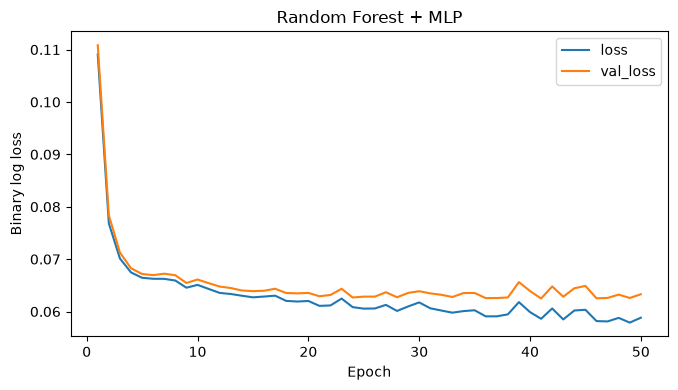

Epoch   1/50  loss=0.10907  val_loss=0.11084
Epoch   2/50  loss=0.07682  val_loss=0.07837
Epoch   3/50  loss=0.07013  val_loss=0.07126
Epoch   4/50  loss=0.06747  val_loss=0.06825
Epoch   5/50  loss=0.06645  val_loss=0.06717
Epoch   6/50  loss=0.06626  val_loss=0.06695
Epoch   7/50  loss=0.06624  val_loss=0.06723
Epoch   8/50  loss=0.06592  val_loss=0.06693
Epoch   9/50  loss=0.06455  val_loss=0.06546
Epoch  10/50  loss=0.06509  val_loss=0.06611
Epoch  11/50  loss=0.06432  val_loss=0.06543
Epoch  12/50  loss=0.06356  val_loss=0.06477
Epoch  13/50  loss=0.06335  val_loss=0.06449
Epoch  14/50  loss=0.06302  val_loss=0.06402
Epoch  15/50  loss=0.06271  val_loss=0.06390
Epoch  16/50  loss=0.06286  val_loss=0.06397
Epoch  17/50  loss=0.06303  val_loss=0.06436
Epoch  18/50  loss=0.06204  val_loss=0.06354
Epoch  19/50  loss=0.06191  val_loss=0.06347
Epoch  20/50  loss=0.06202  val_loss=0.06356
Epoch  21/50  loss=0.06108  val_loss=0.06292
Epoch  22/50  loss=0.06117  val_loss=0.06317
Epoch  23/

In [105]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import log_loss

# Giữ 20% của X_head để đo val_loss. Mỗi giao dịch chỉ cần đi qua rừng một lần.
X_head_train, X_head_val, y_head_train, y_head_val = train_test_split(
    X_head, y_head, test_size=0.2, stratify=y_head, random_state=42
)
tree_features = FunctionTransformer(tree_fraud_probabilities, kw_args={'forest': hybrid_forest})
Z_train = tree_features.fit_transform(X_head_train)
Z_val = tree_features.transform(X_head_val)

head = MLPClassifier(
    hidden_layer_sizes=(64,), activation='relu', batch_size=512,
    random_state=np.random.RandomState(42),
)
epochs = 50
train_losses, val_losses = [], []
fig, ax = plt.subplots(figsize=(7, 4))
train_line, = ax.plot([], [], label='loss')
val_line, = ax.plot([], [], label='val_loss')
ax.set(xlabel='Epoch', ylabel='Binary log loss', title='Random Forest + MLP')
ax.legend()
fig.tight_layout()
chart = display(fig, display_id=True)
plt.close(fig)

for epoch in range(1, epochs + 1):
    # partial_fit chạy một epoch và giữ trạng thái Adam cho epoch tiếp theo.
    head.partial_fit(Z_train, y_head_train, classes=hybrid_forest.classes_)
    train_losses.append(log_loss(y_head_train, head.predict_proba(Z_train), labels=head.classes_))
    val_losses.append(log_loss(y_head_val, head.predict_proba(Z_val), labels=head.classes_))
    print(f'Epoch {epoch:3d}/{epochs}  loss={train_losses[-1]:.5f}  val_loss={val_losses[-1]:.5f}', flush=True)

    train_line.set_data(range(1, epoch + 1), train_losses)
    val_line.set_data(range(1, epoch + 1), val_losses)
    ax.relim()
    ax.autoscale_view()
    chart.update(fig)

rf_mlp_model = make_pipeline(tree_features, head)

## 2.3: GLM-offset boosting

In [106]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

offset_scaler = ColumnTransformer(
    [('numeric', StandardScaler(), numeric_cols)],
    remainder='passthrough',
)
X_offset_train = offset_scaler.fit_transform(X_train_selected)
X_offset_test = offset_scaler.fit_transform(X_test_selected)
X_offset_fit, y_offset_fit = sampling_methods['ADASYN'].fit_resample(X_offset_train, y_train)

glm_model = LogisticRegression(solver='newton-cholesky', max_iter=100)
glm_model.fit(X_offset_fit, y_offset_fit)

# Offset là log-odds của từng giao dịch trước khi boosting.
glm_offset_model = XGBClassifier(
    objective='binary:logistic',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    n_jobs=2,
)
glm_offset_model.fit(
    X_offset_fit, y_offset_fit,
    base_margin=glm_model.decision_function(X_offset_fit),
)

def predict_glm_offset_proba(features):
    features = offset_scaler.transform(features)
    offset = glm_model.decision_function(features)
    fraud_index = list(glm_offset_model.classes_).index(1)
    return glm_offset_model.predict_proba(features, base_margin=offset)[:, fraud_index]

## 2.4. MLP-offset boosting

Đặc trưng đã chuẩn hóa → 32 neuron ReLU → 1 logit cho mỗi giao dịch. XGBoost nhận logit làm `base_margin` và học trên các đặc trưng đã chọn ở mục 1.5.

In [108]:
import numpy as np
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

offset_scaler = StandardScaler()
X_offset_train = offset_scaler.fit_transform(X_train_selected)
X_offset_fit, y_offset_fit = sampling_methods['ADASYN'].fit_resample(X_offset_train, y_train)
offset_mlp = MLPClassifier(
    hidden_layer_sizes=(25,), activation="relu", solver="adam",
    batch_size=512, max_iter=50, random_state=42,
)
offset_mlp.fit(X_offset_fit, y_offset_fit)


def mlp_logit(scaled_features):
    # MLP nhị phân: ReLU ở tầng ẩn, lấy đầu ra tuyến tính trước sigmoid.
    hidden = np.maximum(0, scaled_features @ offset_mlp.coefs_[0] + offset_mlp.intercepts_[0])
    return (hidden @ offset_mlp.coefs_[1] + offset_mlp.intercepts_[1]).ravel()


# Dùng cùng cấu hình cây với GLM-offset để so sánh hai nguồn logit.
mlp_offset_model = clone(glm_offset_model)
mlp_offset_model.fit(X_offset_fit, y_offset_fit, base_margin=mlp_logit(X_offset_fit))


def predict_mlp_offset_proba(features):
    margin = mlp_logit(offset_scaler.transform(features))
    return mlp_offset_model.predict_proba(features, base_margin=margin)[:, 1]

# 3: Evaluate

## 3.1: Traditonal ML

### Decison Tree

In [109]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

# X_test la tap validation duoc tach tu train.csv
y_pred = tree_model.predict(X_test_selected)
y_proba = tree_model.predict_proba(X_test_selected)[:, 1]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.2346
ROC-AUC: 0.8922
              precision    recall  f1-score   support

           0     0.9963    0.8241    0.9021    137654
           1     0.0733    0.8191    0.1346      2338

    accuracy                         0.8240    139992
   macro avg     0.5348    0.8216    0.5183    139992
weighted avg     0.9809    0.8240    0.8893    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[113445  24209]
 [   423   1915]]


#Save submission

In [110]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(tree_model.classes_).index(1)
fraud_probabilities = tree_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/dtree_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()


Đã lưu 299,984 dòng vào D:\ML_Project\submissions\dtree_submission.csv


,id,is_fraud
0,699960,0.039021
1,699961,0.039021
2,699962,0.609243
3,699963,0.120240
4,699964,0.356533


### Random Forest

In [111]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score


y_pred = rf_model.predict(X_test_selected)
y_proba = rf_model.predict_proba(X_test_selected)[:, 1]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.4016
ROC-AUC: 0.9232
              precision    recall  f1-score   support

           0     0.9923    0.9744    0.9833    137654
           1     0.2700    0.5577    0.3638      2338

    accuracy                         0.9674    139992
   macro avg     0.6312    0.7661    0.6736    139992
weighted avg     0.9803    0.9674    0.9729    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[134128   3526]
 [  1034   1304]]


#Save submission

In [112]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(rf_model.classes_).index(1)
fraud_probabilities = rf_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/rf_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()


Đã lưu 299,984 dòng vào D:\ML_Project\submissions\rf_submission.csv


,id,is_fraud
0,699960,0.036447
1,699961,0.019573
2,699962,0.554219
3,699963,0.039393
4,699964,0.099665


### XGboost

In [113]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score


y_pred = xgb_model.predict(X_test_selected)
y_proba = xgb_model.predict_proba(X_test_selected)[:, 1]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.4905
ROC-AUC: 0.938
              precision    recall  f1-score   support

           0     0.9939    0.9696    0.9816    137654
           1     0.2665    0.6510    0.3782      2338

    accuracy                         0.9642    139992
   macro avg     0.6302    0.8103    0.6799    139992
weighted avg     0.9818    0.9642    0.9715    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[133465   4189]
 [   816   1522]]


#Save submission

In [114]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(xgb_model.classes_).index(1)
fraud_probabilities = xgb_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/xgb_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()


Đã lưu 299,984 dòng vào D:\ML_Project\submissions\xgb_submission.csv


,id,is_fraud
0,699960,0.003634
1,699961,0.003967
2,699962,0.630273
3,699963,0.017682
4,699964,0.024455


## 3.2: MLP

### Simple 2 layer MLP

In [115]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

mlp_fraud_index = list(mlp_model.classes_).index(1)
y_pred = mlp_model.predict(X_test_selected)
y_proba = mlp_model.predict_proba(X_test_selected)[:, mlp_fraud_index]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.4387
ROC-AUC: 0.9238
              precision    recall  f1-score   support

           0     0.9869    0.9990    0.9929    137654
           1     0.7960    0.2186    0.3430      2338

    accuracy                         0.9860    139992
   macro avg     0.8914    0.6088    0.6679    139992
weighted avg     0.9837    0.9860    0.9821    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[137523    131]
 [  1827    511]]


#Save submission

In [116]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(mlp_model.classes_).index(1)
fraud_probabilities = mlp_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/mlp_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()

Đã lưu 299,984 dòng vào D:\ML_Project\submissions\mlp_submission.csv


,id,is_fraud
0,699960,0.000403
1,699961,0.000211
2,699962,0.193993
3,699963,0.001229
4,699964,0.001436


### Random Forest + MLP

In [117]:
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, roc_auc_score

fraud_index = list(rf_mlp_model.classes_).index(1)
rf_mlp_proba = rf_mlp_model.predict_proba(X_test_selected)[:, fraud_index]
rf_mlp_pred = (rf_mlp_proba >= 0.5).astype(int)

print('Average Precision:', round(average_precision_score(y_test, rf_mlp_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, rf_mlp_proba), 4))
print(classification_report(y_test, rf_mlp_pred, digits=4, zero_division=0))
print(confusion_matrix(y_test, rf_mlp_pred, labels=[0, 1]))

Average Precision: 0.4144
ROC-AUC: 0.9261
              precision    recall  f1-score   support

           0     0.9868    0.9986    0.9926    137654
           1     0.7201    0.2113    0.3267      2338

    accuracy                         0.9855    139992
   macro avg     0.8534    0.6049    0.6597    139992
weighted avg     0.9823    0.9855    0.9815    139992

[[137462    192]
 [  1844    494]]


#Save submission

In [118]:
print(rf_mlp_model.classes_)

[0 1]


In [119]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(rf_mlp_model.classes_).index(1)
fraud_probabilities = rf_mlp_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/rf_mlp_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()

Đã lưu 299,984 dòng vào D:\ML_Project\submissions\rf_mlp_submission.csv


,id,is_fraud
0,699960,0.000885
1,699961,0.000675
2,699962,0.046465
3,699963,0.000790
4,699964,0.006381


## 3.3: GLM-offset boosting

In [120]:
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, roc_auc_score

glm_offset_proba = predict_glm_offset_proba(X_test_selected)
glm_offset_pred = (glm_offset_proba >= 0.5).astype(int)

print('Average Precision:', round(average_precision_score(y_test, glm_offset_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, glm_offset_proba), 4))
print(classification_report(y_test, glm_offset_pred, digits=4, zero_division=0))
print('Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự lớp: 0, 1)')
print(confusion_matrix(y_test, glm_offset_pred, labels=[0, 1]))

Average Precision: 0.1637
ROC-AUC: 0.8889
              precision    recall  f1-score   support

           0     0.9931    0.9279    0.9594    137654
           1     0.1274    0.6202    0.2114      2338

    accuracy                         0.9227    139992
   macro avg     0.5603    0.7740    0.5854    139992
weighted avg     0.9786    0.9227    0.9469    139992

Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự lớp: 0, 1)
[[127724   9930]
 [   888   1450]]


#Save submission

In [121]:
from pathlib import Path

glm_test_data = pd.read_csv('data/test.csv')
glm_submission = pd.read_csv('data/sample_submission.csv')
glm_test_encoded = preprocessor.transform(glm_test_data.loc[:, preprocessor.feature_names_in_])
glm_test_proba = predict_glm_offset_proba(glm_test_encoded.loc[:, selected_cols])

assert glm_test_data['id'].is_unique and glm_submission['id'].is_unique
assert len(glm_test_data) == len(glm_submission)

glm_proba_by_id = pd.Series(glm_test_proba, index=glm_test_data['id'])
glm_submission['is_fraud'] = glm_submission['id'].map(glm_proba_by_id)
assert glm_submission['is_fraud'].between(0, 1).all()

glm_output_path = Path('submissions/glm_offset_boosting_submission.csv')
glm_output_path.parent.mkdir(exist_ok=True)
glm_submission.to_csv(glm_output_path, index=False)
print(f'Đã lưu {len(glm_submission):,} dòng vào {glm_output_path}')
glm_submission.head()

Đã lưu 299,984 dòng vào submissions\glm_offset_boosting_submission.csv


,id,is_fraud
0,699960,0.000062
1,699961,0.000009
2,699962,0.577138
3,699963,0.000106
4,699964,0.000337


## 3.4. So sánh MLP-offset và GLM-offset

In [122]:
from sklearn.metrics import average_precision_score, roc_auc_score

mlp_offset_proba = predict_mlp_offset_proba(X_test_selected)
offset_results = pd.DataFrame([
    {
        "Mô hình": name,
        "Average Precision": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    for name, proba in [
        ("GLM-offset", glm_offset_proba),
        ("MLP 32-offset", mlp_offset_proba),
    ]
])
display(offset_results.set_index("Mô hình").round(4))

,Average Precision,ROC-AUC
Mô hình,,
GLM-offset,0.1637,0.8889
MLP 32-offset,0.3473,0.9134


# 4: Tổng hợp kết quả của các thử nghiệm



## 4.1. Dữ liệu và cách đánh giá

Tập `train.csv` có 699.960 giao dịch, trong đó 11.689 giao dịch là gian lận (1,67%). Nếu luôn dự đoán giao dịch hợp lệ, accuracy đã đạt 98,33% dù bỏ sót toàn bộ gian lận. Vì vậy, báo cáo dùng Average Precision (AP) và ROC-AUC để đánh giá khả năng xếp hạng rủi ro, đồng thời dùng precision, recall và F1 của lớp gian lận để đánh giá các cảnh báo ở ngưỡng 0,5.

- **Làm sạch và khám phá.** Dữ liệu huấn luyện không có giá trị thiếu. Cột `id` được loại khỏi đầu vào và dùng để ghép kết quả khi xuất submission. Sau khi so sánh tỷ lệ gian lận theo nhóm, notebook giữ `merchant_category` và `auth_method`, loại `card_type`, `channel` và `device_type` vì tỷ lệ giữa các nhóm ít khác biệt. Các biến số được khảo sát bằng boxplot và tương quan Pearson, sau đó giữ nguyên giá trị.
- **Chia tập và mã hóa.** Chia phân tầng theo `is_fraud` với `random_state=42`, thu được 559.968 giao dịch để huấn luyện và 139.992 giao dịch để đánh giá nội bộ, gồm 2.338 ca gian lận. Bộ mã hóa được khớp trên phần huấn luyện. Hai biến phân loại được mã hóa one-hot, các biến Boolean chuyển thành 0/1.
- **Chọn đặc trưng.** Trên phần huấn luyện, kiểm định χ² xếp hạng 23 cột one-hot và Boolean. Giữ 12 cột điểm cao nhất cùng toàn bộ 13 cột số, thu được **25 đặc trưng**. Ba cột đứng đầu theo χ² là `ip_country_mismatch`, `auth_method_No Authentication` và `is_foreign_transaction`.
- **Xuất dự đoán.** Cùng bộ tiền xử lý và danh sách đặc trưng được áp dụng cho 299.984 giao dịch trong `test.csv`. Mỗi submission chứa xác suất `is_fraud = 1`, ghép theo `id` vào thứ tự của file mẫu.

## 4.2. Sáu phương pháp huấn luyện

| Phương pháp | Cách huấn luyện trong notebook |
|---|---|
| Decision Tree | Một cây sâu tối đa 8 tầng, tối đa 50 nút lá, chọn điểm chia ngẫu nhiên. Trọng số lớp `balanced` làm tăng ảnh hưởng của các ca gian lận khi chọn điểm chia. |
| Random Forest | Lấy trung bình xác suất của 100 cây. Mỗi cây sâu tối đa 8 tầng, mỗi lá có ít nhất 50 mẫu. Trọng số của lớp gian lận gấp 10 lần lớp hợp lệ. |
| XGBoost | Huấn luyện tuần tự 300 cây sâu tối đa 5 tầng, tốc độ học 0,05. Mỗi vòng lấy mẫu 80% số dòng và 80% số cột. Đặt `scale_pos_weight=10` cho lớp gian lận. |
| MLP | Đưa trực tiếp 25 đặc trưng vào hai lớp ẩn ReLU gồm 64 và 32 neuron, sau đó qua đầu ra sigmoid. Dùng Adam, batch 512, tối đa 100 epoch. |
| Random Forest + MLP | Mỗi cây trả về một xác suất gian lận. Vector 100 xác suất đi qua một lớp ẩn ReLU 64 neuron rồi qua sigmoid. Trong 80% dữ liệu dành cho huấn luyện, rừng học trên 75%, MLP học trên 20% và 5% còn lại dùng để theo dõi `val_loss`. Cấu hình đang lưu chạy 50 epoch. |
| GLM-offset boosting | Hồi quy logistic ước lượng log-odds ban đầu cho từng giao dịch. XGBoost dùng giá trị này làm `base_margin`, rồi học phần hiệu chỉnh qua 300 cây sâu tối đa 5 tầng với tốc độ học 0,05. Khi dự đoán, mô hình tính lại offset cho từng giao dịch mới. |

**Diễn biến huấn luyện của Random Forest + MLP.** Ở epoch 1, log loss trên tập học của MLP là 0,10182 và trên tập validation riêng là 0,10233. Validation loss thấp nhất được ghi nhận tại epoch 34 (0,04988). Đến epoch 50, loss tập học tiếp tục giảm còn 0,04525, trong khi validation loss tăng nhẹ lên 0,05035. Kết quả ở mục 3 dùng trọng số epoch 50.

## 4.3. Hiệu năng trên tập đánh giá nội bộ

Các số dưới đây lấy từ mục 3, trên cùng 139.992 giao dịch giữ lại từ `train.csv`. AP và ROC-AUC được tính từ xác suất dự đoán. Ba cột cuối chỉ tính cho lớp gian lận ở ngưỡng mặc định 0,5.

| Phương pháp | AP | ROC-AUC | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| Decision Tree | 0,1893 | 0,8886 | 0,0866 | **0,7699** | 0,1558 |
| Random Forest | 0,4417 | 0,9271 | 0,4051 | 0,4855 | 0,4416 |
| XGBoost | 0,5012 | 0,9429 | 0,3148 | 0,6202 | 0,4176 |
| MLP | 0,4771 | 0,9337 | **0,8150** | 0,2374 | 0,3677 |
| Random Forest + MLP | 0,4526 | 0,9317 | 0,7141 | 0,2746 | 0,3967 |
| GLM-offset boosting | **0,5152** | **0,9449** | 0,7802 | 0,3174 | **0,4512** |

Decision Tree phát hiện được nhiều ca gian lận nhất (1.800/2.338), nhưng cũng tạo 18.974 cảnh báo nhầm. MLP có precision cao nhất, với 555 ca gian lận trong 681 cảnh báo, song bỏ sót 1.783 ca. GLM-offset boosting đạt AP, ROC-AUC và F1 cao nhất trong sáu phương pháp. Ở ngưỡng 0,5, mô hình này phát hiện 742 ca và báo nhầm 209 ca.

Việc thay phép lấy trung bình của rừng bằng MLP đi kèm một đánh đổi trong hai cấu hình đã chạy. AP tăng từ 0,4417 lên 0,4526 và precision tăng từ 0,4051 lên 0,7141, trong khi recall giảm từ 0,4855 xuống 0,2746. Hai cấu hình cũng dùng lượng dữ liệu khác nhau để huấn luyện rừng, nên không thể quy toàn bộ chênh lệch cho riêng lớp MLP.

## 4.4. Kết quả submission thực tế

Bảng ghi lại đủ bảy lượt nộp trong ảnh, sắp theo điểm từ cao xuống thấp. Ảnh chỉ hiển thị điểm, không hiển thị tên chỉ số chấm. Hai lượt nộp của Random Forest + MLP trùng tên file nên được phân biệt theo thứ tự thời gian.

| Phương pháp | File đã nộp | Điểm submission |
|---|---|---:|
| GLM-offset boosting | `glm_offset_boosting_submission.csv` | **0,94713** |
| XGBoost | `xgb_submission.csv` | 0,94441 |
| MLP | `mlp_submission.csv` | 0,93668 |
| Random Forest + MLP | `rf_mlp_submission.csv` | 0,93539 |
| Random Forest | `rf_submission.csv` | 0,92932 |
| Decision Tree | `submission.csv` | 0,89428 |

**GLM-offset boosting đứng đầu cả về AP nội bộ (0,5152) và điểm nộp thực tế (0,94713)**, cao hơn XGBoost 0,00272 điểm submission. Nếu lấy lượt nộp tốt nhất của mỗi phương pháp, thứ tự sáu mô hình trên bảng điểm cũng trùng với thứ tự theo ROC-AUC nội bộ. Riêng Random Forest + MLP tăng 0,12309 điểm giữa hai lượt nộp. Ảnh không ghi cấu hình từng lượt nên chưa đủ căn cứ để xác định thay đổi nào tạo ra mức tăng này.